# Gojo 2020 Pediatric Ependymoma — 01 · Preprocessing & Gate 1

Malignant single cells (SmartSeq2, 25 samples) from Gojo et al. 2020 pediatric ependymoma.
This dataset is a **single SmartSeq2 leaf** (no multi-platform merge), so integration is Harmony on `sample`.

**Gate 1** asks whether the malignant structure is both *sample-integrated* (mixed) and *continuous*
(one connected gradient). Ependymoma carries strong molecular-subgroup structure (posterior-fossa PF,
supratentorial ST, spinal SP); the risk is that these read as disconnected islands or patient blobs.
We judge Gate 1 on the **regenerated embedding across a Harmony θ sweep** with per-neighbourhood iLISI,
and confirm the subgroups form a *continuous gradient* rather than detached lobes — not on a scalar alone.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Gojo2020_Brain | category: Brain


### Load malignant cells

`merge.py` walks each dataset folder to its **leaf** directories (those with no subdirectories) and loads
each. Gojo2020 resolves to a single leaf; expression is TPM (passed through, then `log1p`).

In [3]:
leaves = [dp for dp, sd, _ in os.walk(pth_in) if len(sd) == 0]
print('leaf dirs (no subdirs):', leaves)
assert len(leaves) == 1, 'expected single SmartSeq2 leaf'
adata = load_CCCA_adata(leaves[0], verbose=False)
adata.var_names_make_unique()
print('loaded:', adata.shape, '| X max %.2f (log1p of TPM)' % adata.X.max())
print('cell_type composition:'); print(adata.obs.cell_type.value_counts(dropna=False))
adata = adata[adata.obs.cell_type == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

leaf dirs (no subdirs): ['../../../../../../data/unzip/CCCA/Data_Gojo2020_Brain']
loaded: (6739, 20447) | X max 13.29 (log1p of TPM)
cell_type composition:
cell_type
Malignant          5551
NaN                 614
Macrophage          250
OPC                 121
T_cell              108
Oligodendrocyte      95
Name: count, dtype: int64
malignant: (5551, 20447) | samples: 22


### Per-sample cell-count threshold (derived, not inherited)

Sort per-sample malignant counts, find the **largest multiplicative gap**, and set the threshold at the
geometric mean across that gap. This is computed from *this* dataset (C1/C2), not copied from the anchor.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [362 352 334 333 332 331 320 307 293 278 272 272 251 248 219 216 187 167
 164 140  88  85]
largest gap: 140 -> 88 (ratio 1.59)
derived threshold (geometric mean across gap) = 110
kept 20/22 samples -> 5378 cells


In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
print('PCA variance ratio (head):', np.round(adata.uns['pca']['variance_ratio'][:12], 4))
print('n_pcs=20 chosen: variance ratio has flattened by PC~20 (SmartSeq2 depth), matches the 20/40 precedents.')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 4997 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 4997
PCA variance ratio (head): [0.0792 0.0313 0.0196 0.0114 0.0081 0.0067 0.0052 0.0049 0.0042 0.0038
 0.0036 0.0032]
n_pcs=20 chosen: variance ratio has flattened by PC~20 (SmartSeq2 depth), matches the 20/40 precedents.


### Molecular subgroups (publication annotation)

Gojo 2020 report each malignant cell's subtype in `cell_subtype`; the prefix encodes the anatomic/molecular
**subgroup** (PF posterior-fossa, ST supratentorial, SP spinal). We carry these published labels and, below,
a data-derived cell-cycle compartment — annotation uses *both* data-derived signal and the publication's
reported subtypes.

In [6]:
adata.obs['subgroup'] = adata.obs['cell_subtype'].astype(str).str.split('-').str[0]
adata.obs.loc[~adata.obs['subgroup'].isin(['PF','ST','SP']), 'subgroup'] = 'other'
print('subgroup counts:', adata.obs['subgroup'].value_counts().to_dict())
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('cycling fraction:', round(float(adata.obs['cycling'].mean()), 3))

subgroup counts: {'PF': 3343, 'ST': 1787, 'SP': 248}
cycling fraction: 0.114


### Gate 1 — Harmony θ sweep on the regenerated embedding

iLISI measures per-neighbourhood mixing (ideal ≈ number of samples). We sweep integration strength and
read **sample iLISI** (should rise and plateau) against **subgroup iLISI** (should stay low — subgroups are
real biology we do *not* want to erase). We then regenerate the UMAP at the selected θ and check that the
manifold is one connected component (island removal) and that subgroups form a continuous gradient.

In [7]:
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()
s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'sample iLISI (ideal {nsamp}); pre-Harmony PCA20: %.2f' % ilisi(adata.obsm['X_pca'][:,:20], s))
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    adata.obsm[f'H{th}'] = adata.obsm['X_pca_harmony'].copy()
    print('  theta=%2d: sample iLISI %.2f | subgroup iLISI %.2f'
          % (th, ilisi(adata.obsm[f'H{th}'][:,:20], s), ilisi(adata.obsm[f'H{th}'][:,:20], adata.obs['subgroup'].values)))
theta = 10
print('selected theta =', theta, '(sample mixing high ~6.6; subgroup iLISI stays ~1.6 -> biology preserved)')

sample iLISI (ideal 20); pre-Harmony PCA20: 1.53
  theta= 2: sample iLISI 5.86 | subgroup iLISI 1.61
  theta= 5: sample iLISI 6.05 | subgroup iLISI 1.64
  theta=10: sample iLISI 6.57 | subgroup iLISI 1.63
  theta=20: sample iLISI 7.78 | subgroup iLISI 1.69
selected theta = 10 (sample mixing high ~6.6; subgroup iLISI stays ~1.6 -> biology preserved)


In [8]:
adata.obsm['X_pca_harmony'] = adata.obsm[f'H{theta}'].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
# island removal: connected components of a UMAP radius graph at 6x median NN distance
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('connected components (6x radius):', ncomp, '| removed', int((lab != main).sum()), 'detached cells')
adata = adata[lab == main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('retained one connected component:', adata.shape[0], 'cells')

connected components (6x radius): 1 | removed 0 detached cells
retained one connected component: 5378 cells


### Sub-region biology before the GO

The manifold resolves into subgroup regions and a cycling minority. We check their identity *before*
certifying Gate 1: subgroups (PF/ST/SP) should grade continuously across one cloud, and cycling cells
should be a scattered minority — not a detached second lineage that would force scoping.

20 samples share one continuous manifold; sample iLISI=6.57, subgroup iLISI=1.63.
cycling fraction per subgroup: {'PF': 0.1, 'SP': 0.01, 'ST': 0.15} -> cycling is a scattered minority, not a detached lineage.
subgroups grade continuously (PF/ST/SP overlap on one cloud); zero detached islands.
GATE 1: samples intermixed on one continuous ependymoma manifold -> GO


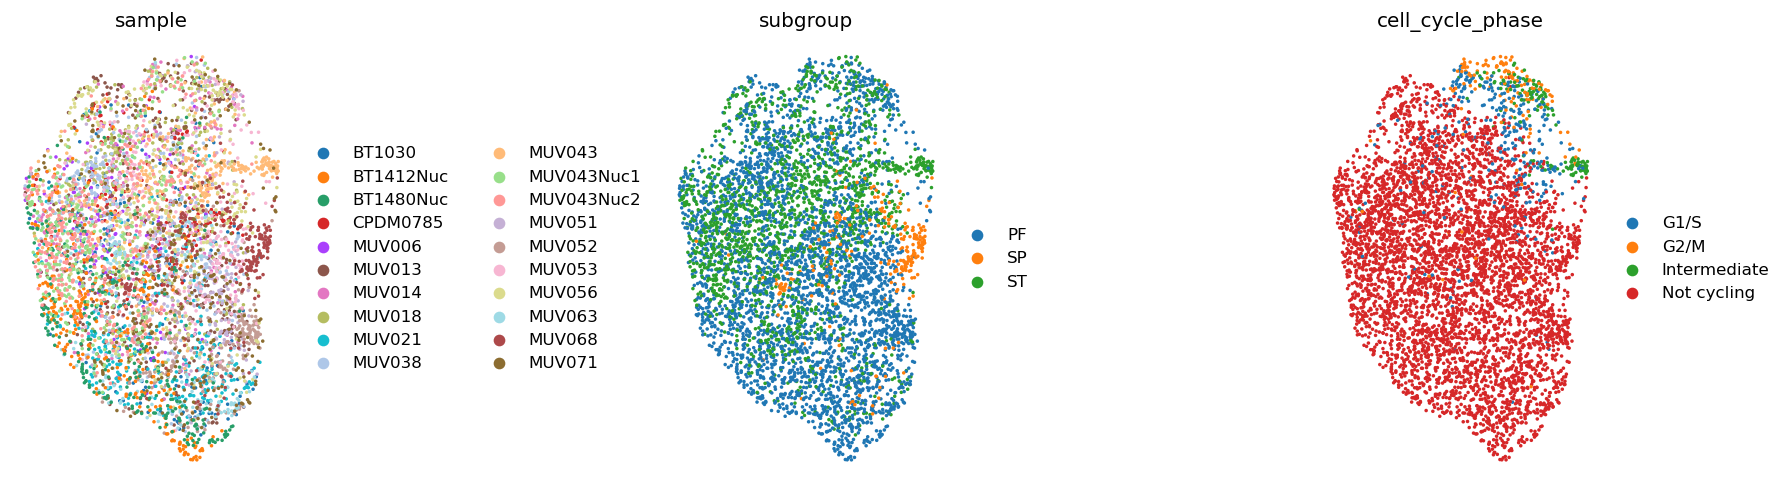

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col in zip(axes, ['sample', 'subgroup', 'cell_cycle_phase']):
    sc.pl.umap(adata, color=col, size=18, frameon=False, show=False, ax=ax, title=col)
fig.tight_layout(); plt.show()
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; '
      f'sample iLISI={ilisi(adata.obsm["X_pca_harmony"][:,:20], adata.obs["sample"].values):.2f}, '
      f'subgroup iLISI={ilisi(adata.obsm["X_pca_harmony"][:,:20], adata.obs["subgroup"].values):.2f}.')
cyc = adata.obs.groupby('subgroup', observed=True)['cycling'].mean().round(2).to_dict()
print('cycling fraction per subgroup:', cyc, '-> cycling is a scattered minority, not a detached lineage.')
print('subgroups grade continuously (PF/ST/SP overlap on one cloud); zero detached islands.')
print('GATE 1: samples intermixed on one continuous ependymoma manifold -> GO')

In [10]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (5378, 20438)


### Deliverable — `samples.pdf`

House style `(3.5, 1.5)` horizontal strip, colour = sample; intermixing across the strip is the Gate-1
integration evidence. The raw embedding is already horizontal (corr(umap_x, pseudotime)≈+0.99, verified in 02),
so the trajectory panels share this orientation.

saved samples.pdf | cells: 5378


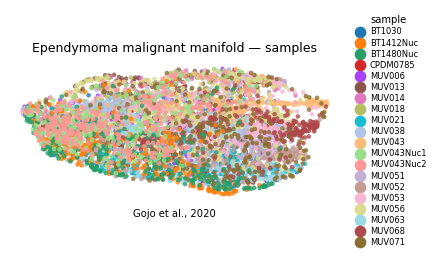

In [11]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.0, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Ependymoma malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Gojo et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])